In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("weather.csv")

In [3]:
df

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...,...
1456,2015-12-27,8.6,4.4,1.7,2.9,rain
1457,2015-12-28,1.5,5.0,1.7,1.3,rain
1458,2015-12-29,0.0,7.2,0.6,2.6,fog
1459,2015-12-30,0.0,5.6,-1.0,3.4,sun


In [4]:
df['weather'].value_counts()

weather
rain       641
sun        640
fog        101
drizzle     53
snow        26
Name: count, dtype: int64

In [5]:
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [6]:
df.describe

<bound method NDFrame.describe of             date  precipitation  temp_max  temp_min  wind  weather
0     2012-01-01            0.0      12.8       5.0   4.7  drizzle
1     2012-01-02           10.9      10.6       2.8   4.5     rain
2     2012-01-03            0.8      11.7       7.2   2.3     rain
3     2012-01-04           20.3      12.2       5.6   4.7     rain
4     2012-01-05            1.3       8.9       2.8   6.1     rain
...          ...            ...       ...       ...   ...      ...
1456  2015-12-27            8.6       4.4       1.7   2.9     rain
1457  2015-12-28            1.5       5.0       1.7   1.3     rain
1458  2015-12-29            0.0       7.2       0.6   2.6      fog
1459  2015-12-30            0.0       5.6      -1.0   3.4      sun
1460  2015-12-31            0.0       5.6      -2.1   3.5      sun

[1461 rows x 6 columns]>

In [7]:
df.shape

(1461, 6)

In [8]:
df.isnull().sum()

date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

In [9]:
df.describe

<bound method NDFrame.describe of             date  precipitation  temp_max  temp_min  wind  weather
0     2012-01-01            0.0      12.8       5.0   4.7  drizzle
1     2012-01-02           10.9      10.6       2.8   4.5     rain
2     2012-01-03            0.8      11.7       7.2   2.3     rain
3     2012-01-04           20.3      12.2       5.6   4.7     rain
4     2012-01-05            1.3       8.9       2.8   6.1     rain
...          ...            ...       ...       ...   ...      ...
1456  2015-12-27            8.6       4.4       1.7   2.9     rain
1457  2015-12-28            1.5       5.0       1.7   1.3     rain
1458  2015-12-29            0.0       7.2       0.6   2.6      fog
1459  2015-12-30            0.0       5.6      -1.0   3.4      sun
1460  2015-12-31            0.0       5.6      -2.1   3.5      sun

[1461 rows x 6 columns]>

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB


<Axes: >

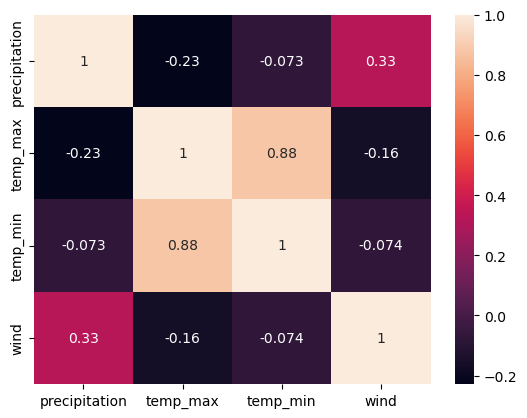

In [12]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

#### data preprocessing

In [13]:
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [14]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
le=LabelEncoder()

In [15]:
x=df.drop(columns=["weather","date"])

In [16]:
y=df["weather"]

In [17]:
le=LabelEncoder()
y=le.fit_transform(y)

In [18]:
y

array([0, 2, 2, ..., 1, 4, 4], shape=(1461,))

In [20]:
scaler=StandardScaler()
x=scaler.fit_transform(x)

In [21]:
x

array([[-0.45364986, -0.49529914, -0.64421175,  1.01497975],
       [ 1.17859791, -0.79473121, -1.08234662,  0.87583314],
       [-0.33385186, -0.64501518, -0.20607688, -0.65477956],
       ...,
       [-0.45364986, -1.25748987, -1.52048149, -0.44605965],
       [-0.45364986, -1.47525865, -1.83912504,  0.11052679],
       [-0.45364986, -1.47525865, -2.05819247,  0.18010009]],
      shape=(1461, 4))

In [23]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [26]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [27]:
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [28]:
y_pred=model.predict(x_test)
y_pred

array([4, 2, 4, 4, 2, 2, 4, 4, 2, 4, 4, 4, 2, 4, 4, 2, 4, 2, 4, 4, 2, 4,
       2, 4, 4, 2, 4, 4, 4, 4, 2, 4, 4, 2, 4, 2, 2, 2, 2, 4, 2, 4, 4, 4,
       2, 2, 2, 4, 4, 4, 4, 2, 4, 2, 4, 2, 2, 4, 2, 4, 2, 4, 4, 4, 4, 4,
       2, 4, 2, 2, 2, 4, 4, 4, 2, 2, 4, 4, 2, 2, 2, 2, 2, 4, 2, 4, 4, 2,
       4, 2, 2, 4, 4, 2, 2, 4, 4, 4, 4, 2, 4, 2, 2, 3, 4, 4, 4, 2, 4, 2,
       2, 4, 2, 2, 4, 4, 4, 4, 4, 2, 2, 2, 2, 2, 2, 4, 2, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 2, 2, 2, 4, 4, 4, 2, 2, 4, 4, 4, 2, 4, 4, 2, 4, 4, 4,
       2, 2, 4, 4, 4, 2, 4, 4, 2, 4, 4, 2, 2, 4, 4, 4, 2, 2, 4, 4, 2, 2,
       4, 4, 4, 2, 4, 4, 4, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 2, 4, 4, 4, 2,
       2, 2, 4, 4, 4, 2, 4, 4, 2, 4, 2, 4, 2, 4, 4, 4, 4, 4, 4, 4, 2, 4,
       2, 4, 4, 4, 4, 2, 4, 2, 4, 2, 4, 4, 4, 4, 2, 4, 4, 2, 4, 4, 2, 2,
       4, 2, 4, 4, 4, 4, 2, 2, 2, 2, 2, 4, 4, 4, 2, 4, 2, 2, 2, 4, 4, 4,
       4, 2, 2, 4, 4, 4, 4, 2, 4, 2, 4, 4, 2, 2, 4, 4, 4, 2, 4, 4, 4, 4,
       2, 4, 4, 4, 4, 2, 4])

In [29]:
y_test

array([4, 2, 2, 4, 2, 2, 2, 4, 2, 4, 4, 4, 2, 4, 1, 2, 4, 1, 1, 4, 2, 2,
       2, 4, 1, 2, 4, 4, 1, 4, 2, 4, 4, 3, 4, 2, 2, 2, 2, 4, 2, 4, 1, 4,
       4, 2, 2, 4, 2, 4, 4, 2, 4, 2, 4, 2, 2, 4, 2, 4, 2, 4, 3, 4, 4, 0,
       2, 4, 2, 2, 2, 1, 4, 2, 2, 4, 2, 4, 2, 3, 2, 0, 2, 4, 2, 4, 0, 2,
       1, 2, 2, 4, 4, 2, 2, 4, 4, 2, 4, 2, 4, 4, 2, 3, 2, 4, 4, 2, 4, 2,
       2, 4, 2, 2, 0, 1, 4, 4, 4, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 1, 4, 2, 2, 2, 4, 0, 4, 2, 2, 0, 1, 4, 2, 4, 4, 2, 4, 4, 4,
       2, 2, 1, 4, 2, 2, 4, 4, 2, 4, 4, 2, 2, 4, 4, 4, 2, 2, 1, 4, 2, 2,
       4, 4, 4, 2, 4, 4, 4, 2, 2, 2, 2, 2, 4, 4, 0, 1, 4, 2, 1, 4, 1, 2,
       3, 2, 2, 4, 0, 2, 4, 2, 2, 4, 2, 4, 2, 4, 4, 4, 2, 4, 4, 4, 2, 4,
       2, 4, 4, 4, 1, 2, 4, 2, 4, 2, 4, 2, 4, 4, 2, 4, 4, 4, 0, 1, 3, 2,
       4, 3, 4, 4, 4, 4, 2, 2, 2, 2, 2, 1, 4, 1, 2, 4, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 1, 1, 4, 4, 4, 4, 2, 4, 4, 2, 3, 4, 4, 1, 2, 4, 4, 4, 4,
       2, 4, 4, 2, 1, 2, 4])

In [31]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [32]:
accuracy_score(y_test,y_pred)

0.7781569965870307

In [33]:
confusion_matrix(y_test,y_pred)

array([[  0,   0,   1,   0,   8],
       [  0,   0,   2,   0,  23],
       [  0,   0, 102,   0,  18],
       [  0,   0,   6,   1,   1],
       [  0,   0,   6,   0, 125]])

In [34]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       0.00      0.00      0.00        25
           2       0.87      0.85      0.86       120
           3       1.00      0.12      0.22         8
           4       0.71      0.95      0.82       131

    accuracy                           0.78       293
   macro avg       0.52      0.39      0.38       293
weighted avg       0.70      0.78      0.72       293



In [36]:
from sklearn.ensemble import RandomForestClassifier

In [50]:
rf_model=RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

In [51]:
rf_model=model.fit(x_train,y_train)

In [52]:
y_pred=rf_model.predict(x_test)

In [53]:
accuracy=accuracy_score(y_test,y_pred)

In [54]:
accuracy

0.7781569965870307

In [64]:
import pickle

In [65]:
pickle.dump(rf_model,open('model.pkl','wb'))

In [66]:
try:
    pickle.dump(scaler,open('scaler.pkl','wb'))
    pickle.dump(le,open('le.pkl','wb'))
    print("all done")
except:
    print("error")

all done
